In [1]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

%load_ext autoreload
%autoreload 2

In [ ]:
from TractDensityComponents import TD_PCA
from components import Projections
from nmf import NMFProjections


penalizers = np.arange(0.001, 1.5, 0.1)
l1_ratios = np.arange(0.001, 1, 0.1)


df_training = dataset_training.df
df_testing = dataset_testing.df

training_maps = dataset_training.maps
testing_maps = dataset_testing.maps

normalization = None
n_components= 100


method = TD_PCA(training_maps, T1, binary_mask=T1_brain, n_components=n_components)
trainer = Transformer(method)

comps_training = trainer.fit_transform(norm=normalization)
comps_testing = trainer.transform(testing_maps)

df_base = df_training
df_base = df_base.drop(columns=["OS", "site", "ID"])

X_train_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_training, method, n_components=n_components)

# kolumny_do_usuniecia = ["OS", "site", "ID", "EOR", "MGMT"]
# df_train_clean = df_training.drop(columns=[col for col in kolumny_do_usuniecia if col in df_training.columns])
# df_test_clean = df_testing.drop(columns=[col for col in kolumny_do_usuniecia if col in df_testing.columns])

encoding_pipeline = EncodingPipeline(df_base)
# df_base = DataTransformer.drop_columns(df_base)
X_train = DataTransformer.feature_fit_transform(encoding_pipeline)

df_base = df_testing
df_base = df_base.drop(columns=["OS", "site", "ID"])
# df_base = DataTransformer.drop_columns(df_base)
# X_test = DataTransformer.feature_transform(df_base, encoding_pipeline)
X_test_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_testing, method, n_components=n_components)
X_test = DataTransformer.feature_transform(X_test_with_features, encoding_pipeline)

In [2]:
voxel_res = 1.5
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
rhuh_dir = "Glioblastoma_RHUH-GBM_v2-29102025"
tcga_dir = "Glioblastoma_TCGA-GBM_v1-20170717"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1, 2, 3]
n_jobs = 16
nthreads = 2

In [3]:
DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

Log-rank test: chi-squared statistic of 0.3129840079623018 (p=0.9575683269152051)
INFO: The effect of site was NOT found to be significant, copying OS data as it was


In [4]:
ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

Loading UCSF maps:   0%|          | 0/367 [00:00<?, ?it/s]

Loading UCSF maps: 100%|██████████| 367/367 [00:07<00:00, 48.36it/s]


In [5]:
# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

Loading UPENN maps:   0%|          | 0/496 [00:00<?, ?it/s]

Loading UPENN maps: 100%|██████████| 496/496 [00:11<00:00, 43.78it/s]


In [6]:
rhuh_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==2]["ID"].values]
rhuh_ids = [sub.replace('-0', '-', 1) for sub in rhuh_ids]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{rhuh_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(rhuh_ids, desc="Loading RHUH maps")
)
maps_rhuh = np.vstack(results) # Nsubjects x nFeatures
maps_rhuh = np.where(maps_rhuh>=0, maps_rhuh, 0)

Loading RHUH maps:   0%|          | 0/33 [00:00<?, ?it/s]

Loading RHUH maps: 100%|██████████| 33/33 [00:00<00:00, 234.37it/s]


In [7]:
def delete_second_zero(text):
    splits = text.split('-')
    if len(splits) >= 3 and splits[2].startswith('0'):
        splits[2] = splits[2][1:]
    return '-'.join(splits)

In [8]:
tcga_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==3]["ID"].values]
tcga_ids = [delete_second_zero(sub) for sub in tcga_ids]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{tcga_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(tcga_ids, desc="Loading TCGA maps")
)
maps_tcga = np.vstack(results)
maps_tcga = np.where(maps_tcga>=0, maps_tcga, 0)

Loading TCGA maps:   0%|          | 0/103 [00:00<?, ?it/s]

Loading TCGA maps: 100%|██████████| 103/103 [00:00<00:00, 128.26it/s]


In [9]:
maps_all = np.vstack((maps_ucsf, maps_upenn, maps_rhuh, maps_tcga))

In [10]:
maps_training = np.vstack((maps_ucsf, maps_upenn))
maps_testing = np.vstack((maps_rhuh, maps_tcga))

In [11]:
from dataclasses import dataclass, field


@dataclass
class Dataset:
    name: str
    path: str
    maps: np.ndarray
    df: pd.DataFrame

    def __str__(self):
        return self.name.upper()
    
from typing import TypeAlias, Union
from KernelPCA import TD_Kernel_PCA
from TractDensityComponents import TD_PCA
from nmf import NMFProjections


Projector: TypeAlias = Union[TD_Kernel_PCA, TD_PCA, NMFProjections]

class Transformer:
    def __init__(self, projector: Projector):
        self.projector = projector

    def fit_transform(self, norm, **kwargs):
        return self.projector.fit_transform_maps(norm=norm, **kwargs)
    
    def transform(self, maps):
        return self.projector.transform_maps(maps)

    
from lifelines import CoxPHFitter


class TD_CoxPHFitter:
    def __init__(self, penalizer: float | int = 0.01, l1_ratio: float = 0.0):
        self.penalizer = penalizer
        self.l1_ratio = l1_ratio
        self._cph = CoxPHFitter(penalizer=penalizer, l1_ratio=l1_ratio)
    
    def fit(self, X_train: pd.DataFrame, duration_col: str, event_col: str, **kwargs):
        self._cph.fit(X_train, duration_col, event_col=event_col, **kwargs)

    def score(self, X_test: pd.DataFrame, scoring_method: str = "log_likelihood", **kwargs):
        return self._cph.score(X_test, scoring_method, **kwargs)
    
    def plot(self, ax):
        self._cph.plot(ax=ax)
    
    @property
    def concordance_index(self):
        if not hasattr(self._cph, "concordance_index_"):
            raise ValueError("CoxPHFitter not fitted yet. Fit it first")
        return self._cph.concordance_index_
    
    @property
    def cph(self):
        return self._cph
    
from dataclasses import dataclass
import matplotlib.pyplot as plt

@dataclass
class ModelConfig:
    penalizer: float = 0.01
    duration_col: str = 'OS (corrected)'
    event_col: str = 'status'
    n_components: int = 100

from enum import Enum

from pipeline_encoder import EncodingPipeline


class DataTransformer:
    class FeatureMethod(Enum):
        COSINE = "Cos"
        RBF = "RBF"
        PCA = "PCA"
        NMF = "NMF"

    COMPONENT_PREFIX = "Comp"
    COLUMNS_TO_DROP = ["volume", "site", "OS", "ID", "ltdi", "tdi"]
    NUMERICAL_COLUMNS_TO_DROP = ["OS (corrected)", "status"]

    @staticmethod
    def add_extracted_mapsdata(df_base: pd.DataFrame, extracted_features: np.ndarray, method: FeatureMethod, n_components: int, column_names: list[str] | None = None) -> pd.DataFrame:
        if column_names is None:
            column_names = [f"{method.value}_{DataTransformer.COMPONENT_PREFIX}_{i+1}" for i in range(n_components)]
        
        df_new_features = pd.DataFrame(
            extracted_features,
            columns=column_names, 
            index=df_base.index
        )

        df_all = pd.concat([df_base, df_new_features], axis=1)

        return df_all
    
    @staticmethod
    def drop_columns(df_base: pd.DataFrame):
        columns_to_drop = DataTransformer.COLUMNS_TO_DROP
        df_base = df_base.drop(columns=columns_to_drop)

        return df_base
    
    @staticmethod
    def feature_fit_transform(encoding_pipeline: EncodingPipeline):
        df_base = encoding_pipeline.df
        
        categorical_features = df_base.select_dtypes(include="object").columns
        numerical_features = df_base.select_dtypes(exclude="object").columns

        numerical_features = numerical_features.drop(DataTransformer.NUMERICAL_COLUMNS_TO_DROP)

        X_transformed = encoding_pipeline.fit_transform(list(numerical_features), list(categorical_features))

        return X_transformed
    

    @staticmethod
    def feature_transform(test_df: pd.DataFrame, encoding_pipeline: EncodingPipeline):
        X_transformed = encoding_pipeline.transform(test_df)
        
        return X_transformed


## Datasets

In [12]:
import pandas as pd
import os

def save_results(results_dict, filename="results_survival.csv"):
    if 'covariates' in results_dict and isinstance(results_dict['covariates'], (list, pd.Index)):
        results_dict['covariates'] = ", ".join(map(str, results_dict['covariates']))
        
    df_new = pd.DataFrame([results_dict])
    
    if os.path.isfile(filename):
        df_new.to_csv(filename, mode='a', header=False, index=False)
    else:
        df_new.to_csv(filename, mode='w', header=True, index=False)

In [13]:
UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()
data_rhuh = DATA[DATA['site'] == 2].copy()
data_tcga = DATA[DATA['site'] == 3].copy()

# dataset_training = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_testing = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# dataset_testing = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_training = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# dataset_training = Dataset("ucsf+upenn", "path/3", maps_all, DATA)
# dataset_testing = Dataset("ucsf+upenn", "path/3", maps_all, DATA)
# dataset_training = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_testing = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# dataset_training = Dataset("upenn", "path/1", maps_upenn, data_upenn)
# dataset_testing = Dataset("tcga", "path/4", maps_tcga, data_tcga)
# dataset_training = Dataset("upenn", "path/1", maps_upenn, data_upenn)
# dataset_testing = Dataset("tcga", "path/4", maps_tcga, data_tcga)

In [ ]:
UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()
data_rhuh = DATA[DATA['site'] == 2].copy()
data_tcga = DATA[DATA['site'] == 3].copy()

data_training = pd.concat([data_ucsf, data_upenn], ignore_index=True)
data_testing = pd.concat([data_rhuh, data_tcga], ignore_index=True)

dataset_training = Dataset("ucsf+upenn", "path/1", maps_training, data_training)
dataset_testing = Dataset("rhuh+tcga", "path/2", maps_testing, data_testing)

: 

In [ ]:
from TractDensityComponents import TD_PCA
from components import Projections
from nmf import NMFProjections


penalizers = np.arange(0.001, 1.5, 0.1)
l1_ratios = np.arange(0.001, 1, 0.1)


df_training = dataset_training.df
df_testing = dataset_testing.df

training_maps = dataset_training.maps
testing_maps = dataset_testing.maps

normalization = None
n_components= 100


method = TD_PCA(training_maps, T1, binary_mask=T1_brain, n_components=n_components)
trainer = Transformer(method)

comps_training = trainer.fit_transform(norm=normalization)
comps_testing = trainer.transform(testing_maps)

df_base = df_training
df_base = df_base.drop(columns=["OS", "site", "ID"])

X_train_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_training, method, n_components=n_components)

# kolumny_do_usuniecia = ["OS", "site", "ID", "EOR", "MGMT"]
# df_train_clean = df_training.drop(columns=[col for col in kolumny_do_usuniecia if col in df_training.columns])
# df_test_clean = df_testing.drop(columns=[col for col in kolumny_do_usuniecia if col in df_testing.columns])

encoding_pipeline = EncodingPipeline(df_base)
# df_base = DataTransformer.drop_columns(df_base)
X_train = DataTransformer.feature_fit_transform(encoding_pipeline)

df_base = df_testing
df_base = df_base.drop(columns=["OS", "site", "ID"])
# df_base = DataTransformer.drop_columns(df_base)
# X_test = DataTransformer.feature_transform(df_base, encoding_pipeline)
X_test_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_testing, method, n_components=n_components)
X_test = DataTransformer.feature_transform(X_test_with_features, encoding_pipeline)

for penalizer in penalizers:
    for l1_ratio in l1_ratios:
        td_cphfitter = TD_CoxPHFitter(penalizer, l1_ratio)
        try:
            td_cphfitter.fit(X_train, duration_col, event_col)
        except:
            continue

        train_c_index = td_cphfitter.concordance_index

        c_index_test = td_cphfitter.score(X_test, "concordance_index")

    # fig, ax = plt.subplots(figsize=(12, 20))
    # ax.set_title(f"Baseline model trained on {dataset_training.name.upper()}.\n Penalizer: {penalizer:.4f}\n Training Concordance Index on {dataset_training.name.upper()}: {td_cphfitter.concordance_index:.4f} \n Testing Concordance Index on {dataset_testing.name.upper()}: {c_index_test:.4f}")
    # td_cphfitter.plot(ax = ax)

    # plot_filename = f"results/1/cox_plot_penalizer_{penalizer:.3f}.png"
    # fig.savefig(plot_filename, bbox_inches='tight')
    # plt.close(fig)

        clean_covariates = [col for col in X_train.columns if col not in [duration_col, event_col]]

        results = {
            "extraction_method": "PCA",
            "training_dataset": dataset_training.name,
            "testing_dataset": dataset_testing.name,
            "penalizer": penalizer,
            "l1_ratio": l1_ratio,
            "cox_method": "CoxPHFitter",
            "ci_training": round(train_c_index, 5),
            "ci_testing": round(c_index_test, 5),
            "covariates": clean_covariates,
            "duration_col": duration_col,
            "event_col": event_col
        }

        save_results(results, "results_ucsf_upenn_rhuh_tcga.csv")

In [15]:
from TractDensityComponents import TD_PCA
from components import Projections
from nmf import NMFProjections
import sklearn


normalization = None#'min_max'
# save_dir = "results/"
n_components = 100

sklearn.set_config(transform_output="default")

UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()

penalizer = 0.1
duration_col = 'OS (corrected)'
event_col = 'status'

In [173]:
class Datasets:
    UCSF = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
    UPENN = Dataset("upenn", "path/2", maps_upenn, data_upenn)
    RHUH = Dataset("rhuh", "path/3", maps_rhuh, data_rhuh)
    TCGA = Dataset("tcga", "path/4", maps_tcga, data_tcga)


import itertools


possibilities = [Datasets.UCSF, Datasets.UPENN, Datasets.RHUH, Datasets.TCGA]
pairs = list(itertools.permutations(possibilities, 2))

In [31]:
# dataset_training = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_testing = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# dataset_testing = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_training = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# dataset_training = Dataset("ucsf+upenn", "path/3", maps_all, DATA)
# dataset_testing = Dataset("ucsf+upenn", "path/3", maps_all, DATA)

# df_training = dataset_training.df
# df_testing = dataset_testing.df

# training_maps = dataset_training.maps
# testing_maps = dataset_testing.maps


# df_base = df_training
# df_base = df_base.drop(columns=["OS", "site"])

# encoding_pipeline = EncodingPipeline(df_base)
# X_train = DataTransformer.feature_fit_transform(encoding_pipeline)

# df_base = df_testing
# df_base = df_base.drop(columns=["OS", "site"])
# X_test = DataTransformer.feature_transform(df_base, encoding_pipeline)

penalizers = np.arange(0.001, 1.5, 0.1)
l1_ratios = np.arange(0.001, 1, 0.1)

for (dataset_training, dataset_testing) in pairs:
    df_training = dataset_training.df
    df_testing = dataset_testing.df

    training_maps = dataset_training.maps
    testing_maps = dataset_testing.maps


    df_base = df_training
    df_base = df_base.drop(columns=["OS", "site", "ID"])
    # kolumny_do_usuniecia = ["OS", "site", "ID", "EOR", "MGMT"]
    # df_train_clean = df_training.drop(columns=[col for col in kolumny_do_usuniecia if col in df_training.columns])
    # df_test_clean = df_testing.drop(columns=[col for col in kolumny_do_usuniecia if col in df_testing.columns])

    encoding_pipeline = EncodingPipeline(df_base)
    # df_base = DataTransformer.drop_columns(df_base)
    X_train = DataTransformer.feature_fit_transform(encoding_pipeline)

    df_base = df_testing
    df_base = df_base.drop(columns=["OS", "site", "ID"])
    # df_base = DataTransformer.drop_columns(df_base)
    X_test = DataTransformer.feature_transform(df_base, encoding_pipeline)

    for penalizer in penalizers:
        for l1_ratio in l1_ratios:
            td_cphfitter = TD_CoxPHFitter(penalizer, l1_ratio)
            try:
                td_cphfitter.fit(X_train, duration_col, event_col)
            except:
                continue

            train_c_index = td_cphfitter.concordance_index

            c_index_test = td_cphfitter.score(X_test, "concordance_index")

        # fig, ax = plt.subplots(figsize=(12, 20))
        # ax.set_title(f"Baseline model trained on {dataset_training.name.upper()}.\n Penalizer: {penalizer:.4f}\n Training Concordance Index on {dataset_training.name.upper()}: {td_cphfitter.concordance_index:.4f} \n Testing Concordance Index on {dataset_testing.name.upper()}: {c_index_test:.4f}")
        # td_cphfitter.plot(ax = ax)

        # plot_filename = f"results/1/cox_plot_penalizer_{penalizer:.3f}.png"
        # fig.savefig(plot_filename, bbox_inches='tight')
        # plt.close(fig)

            clean_covariates = [col for col in X_train.columns if col not in [duration_col, event_col]]

            results = {
                "extraction_method": "PCA",
                "training_dataset": dataset_training.name,
                "testing_dataset": dataset_testing.name,
                "penalizer": penalizer,
                "l1_ratio": l1_ratio,
                "cox_method": "CoxPHFitter",
                "ci_training": round(train_c_index, 5),
                "ci_testing": round(c_index_test, 5),
                "covariates": clean_covariates,
                "duration_col": duration_col,
                "event_col": event_col
            }

            save_results(results)

NameError: name 'pairs' is not defined

In [34]:
import pandas as pd

# 1. Wczytanie pliku CSV do nowego DataFrame
# df = pd.read_csv("results_survival.csv")
df = pd.read_csv("results_ucsf_upenn_rhuh_tcga.csv")

# 2. (Opcjonalnie) Przywrócenie kolumny 'covariates' z tekstu z powrotem do formy listy Pythona
# if 'covariates' in df_results.columns:
#     df_results['covariates'] = df_results['covariates'].apply(
#         lambda x: x.split(', ') if isinstance(x, str) else x
#     )

In [35]:
df.loc[df["ci_testing"].idxmax()]

extraction_method                                       PCA
training_dataset                                 ucsf+upenn
testing_dataset                                   rhuh+tcga
penalizer                                             0.501
l1_ratio                                              0.501
cox_method                                      CoxPHFitter
ci_training                                         0.65647
ci_testing                                          0.64796
covariates           sex, age, volume, ltdi, tdi, EOR, MGMT
duration_col                                 OS (corrected)
event_col                                            status
Name: 55, dtype: object

In [36]:
import pandas as pd

# Wczytanie wyników
# df = pd.read_csv("results_survival.csv")

# 1. Znajdujemy wiersze z najlepszym ci_testing dla KAŻDEGO penalizera
best_combinations = df.loc[df.groupby('penalizer')['ci_testing'].idxmax()]

# 2. Sortujemy od absolutnie najlepszego wyniku testowego w dół
best_combinations = best_combinations.sort_values(by='ci_testing', ascending=False)

print("Top 10 najlepszych kombinacji (Penalizer + L1_Ratio):")
display(best_combinations[['penalizer', 'l1_ratio', 'ci_training', 'ci_testing']].head(10))

Top 10 najlepszych kombinacji (Penalizer + L1_Ratio):


,penalizer,l1_ratio,ci_training,ci_testing
55,0.501,0.501,0.65647,0.64796
232,1.201,0.201,0.65719,0.64671
242,1.301,0.201,0.65606,0.64671
38,0.301,0.801,0.65716,0.64657
83,0.801,0.301,0.65716,0.64657
64,0.601,0.401,0.65718,0.64643
46,0.401,0.601,0.65718,0.64643
93,0.901,0.301,0.65578,0.64601
74,0.701,0.401,0.65549,0.64559
252,1.401,0.201,0.65550,0.64545


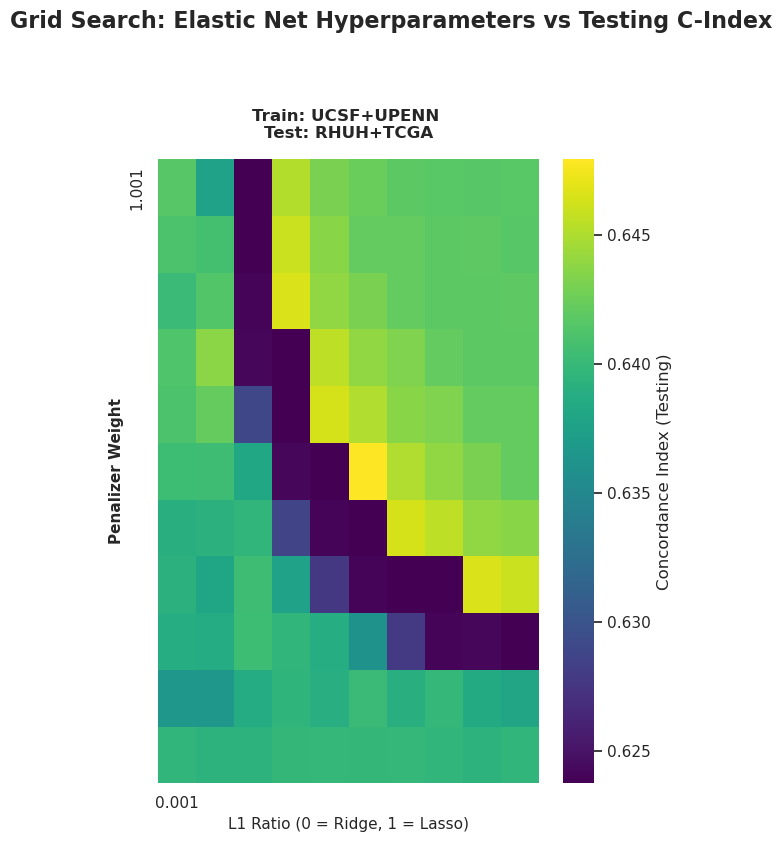

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Przygotowanie danych (zaokrąglanie hiperparametrów)
df['penalizer_round'] = df['penalizer'].round(3)
df['l1_ratio_round'] = df['l1_ratio'].round(3)

# 2. Stworzenie kolumny grupującej (tak jak robiliśmy to na wykresie liniowym)
df['training_testing_configuration'] = "Train: " + df['training_dataset'].str.upper() + " \nTest: " + df['testing_dataset'].str.upper()

# Zbieramy wszystkie unikalne konfiguracje (powinny być 3)
unique_configs = df['training_testing_configuration'].unique()
n_configs = len(unique_configs)

# 3. Ustalamy WSPÓLNĄ skalę kolorów dla wszystkich wykresów!
global_vmin = df['ci_testing'].min()
global_vmax = df['ci_testing'].max()

# 4. Tworzymy siatkę wykresów (1 wiersz, 3 kolumny)
# Używamy sharey=True, żeby oś Y (Penalizer) była wspólna i nie powtarzała się 3 razy
fig, axes = plt.subplots(1, n_configs, figsize=(6 * n_configs, 8), sharey=True)

# Zabezpieczenie, gdyby była tylko 1 konfiguracja
if n_configs == 1: axes = [axes]

# 5. Pętla rysująca mapę ciepła dla każdej konfiguracji
for i, (ax, config) in enumerate(zip(axes, unique_configs)):
    
    # Filtrujemy dane tylko dla obecnej grupy
    df_subset = df[df['training_testing_configuration'] == config]
    
    # Tworzymy tabelę przestawną
    heatmap_data = df_subset.pivot_table(
        values='ci_testing', 
        index='penalizer_round', 
        columns='l1_ratio_round'
    )
    heatmap_data = heatmap_data.sort_index(ascending=False)
    
    # Rysujemy mapę ciepła
    sns.heatmap(
        heatmap_data, 
        cmap='viridis',
        vmin=global_vmin, # Stałe minimum
        vmax=global_vmax, # Stałe maksimum
        xticklabels=10,   
        yticklabels=20 if i == 0 else False, # Pokaż etykiety osi Y tylko na pierwszym wykresie z lewej
        ax=ax,
        cbar=(i == n_configs - 1), # Pokaż pasek legendy tylko na OSTATNIM wykresie z prawej
        cbar_kws={'label': 'Concordance Index (Testing)'} if (i == n_configs - 1) else None
    )
    
    # Podpisy dla każdego sub-wykresu
    ax.set_title(config, fontsize=12, fontweight='bold', pad=15)
    ax.set_xlabel("L1 Ratio (0 = Ridge, 1 = Lasso)", fontsize=11)
    
    if i == 0:
        ax.set_ylabel("Penalizer Weight", fontsize=11, fontweight='bold')
    else:
        ax.set_ylabel("") # Czyścimy podpis osi Y dla środkowego i prawego wykresu

# Główny, duży tytuł dla całego obrazka
plt.suptitle("Grid Search: Elastic Net Hyperparameters vs Testing C-Index", fontsize=16, fontweight='bold', y=1.05)

plt.tight_layout()
plt.show()

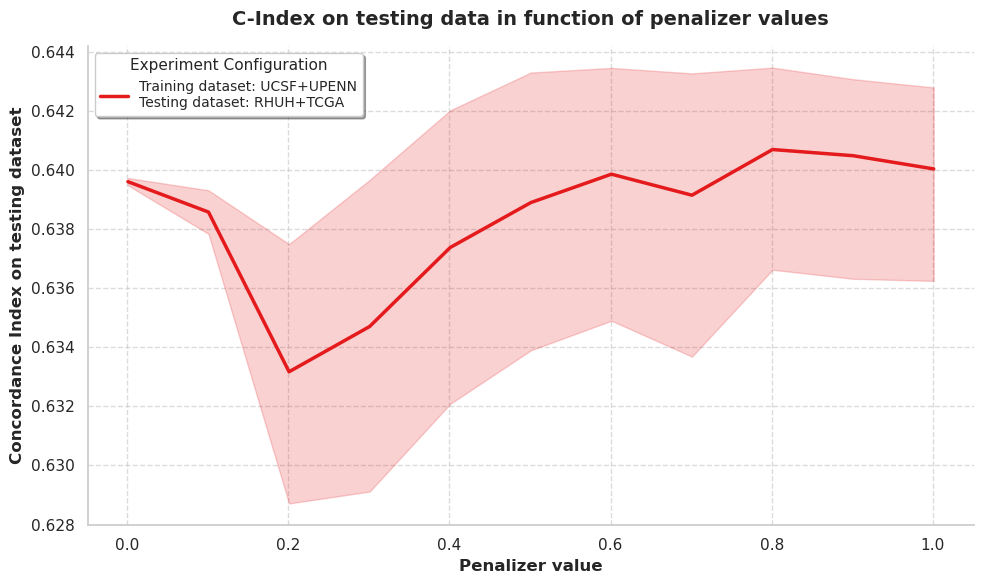

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

df['training_testing_configuration'] = "Training dataset: " + df['training_dataset'].str.upper() + "\nTesting dataset: " + df['testing_dataset'].str.upper()

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

sns.lineplot(
    data=df, 
    x='penalizer', 
    y='ci_testing', 
    hue='training_testing_configuration', 
    linewidth=2.5,
    palette='Set1',
    ax=ax
)

ax.set_title("C-Index on testing data in function of penalizer values", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Penalizer value", fontsize=12, fontweight='bold')
ax.set_ylabel("Concordance Index on testing dataset", fontsize=12, fontweight='bold')

ax.grid(True, which='both', linestyle='--', alpha=0.7)

ax.legend(title="Experiment Configuration", title_fontsize='11', fontsize='10', frameon=True, shadow=True)

sns.despine(ax=ax)

plt.tight_layout()
plt.show()

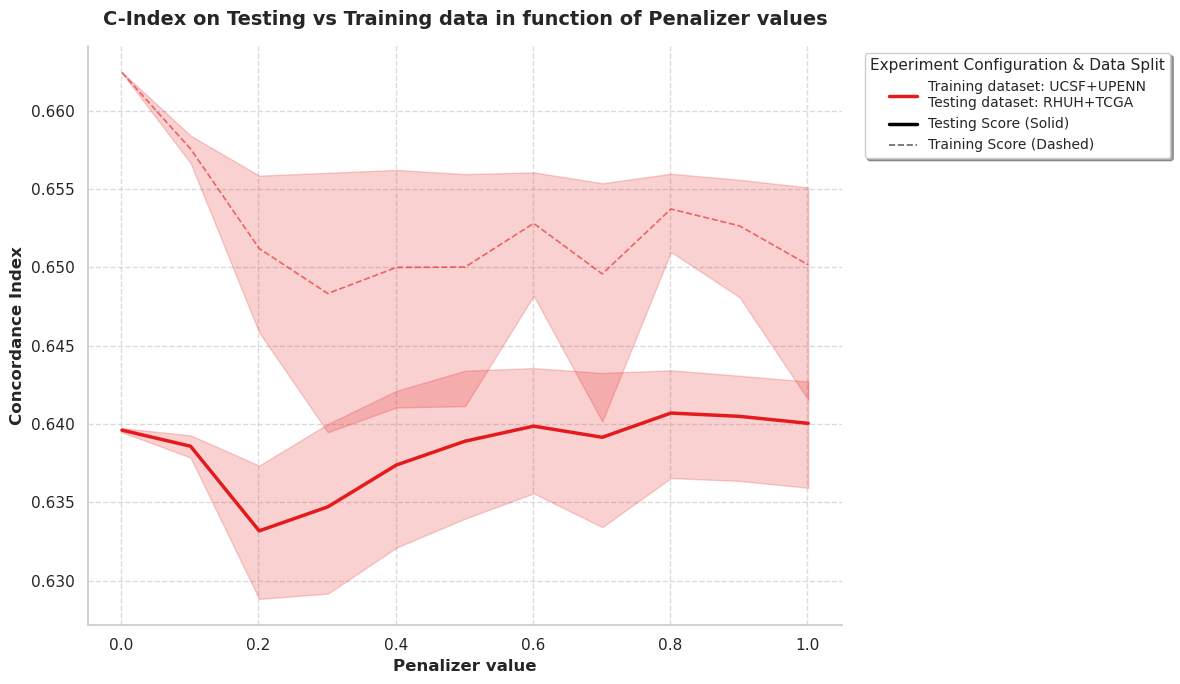

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D


df['training_testing_configuration'] = "Training dataset: " + df['training_dataset'].str.upper() + "\nTesting dataset: " + df['testing_dataset'].str.upper()

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 7))

sns.lineplot(
    data=df, 
    x='penalizer', 
    y='ci_testing', 
    hue='training_testing_configuration', 
    linewidth=2.5,
    palette='Set1',
    ax=ax
)

sns.lineplot(
    data=df, 
    x='penalizer', 
    y='ci_training', 
    hue='training_testing_configuration', 
    linewidth=1.2,
    linestyle='--',
    alpha=0.6,
    palette='Set1',
    legend=False,
    ax=ax
)

ax.set_title("C-Index on Testing vs Training data in function of Penalizer values", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Penalizer value", fontsize=12, fontweight='bold')
ax.set_ylabel("Concordance Index", fontsize=12, fontweight='bold')

ax.grid(True, which='both', linestyle='--', alpha=0.7)

handles, labels = ax.get_legend_handles_labels()

line_test = Line2D([0], [0], color='black', linewidth=2.5, label='Testing Score (Solid)')
line_train = Line2D([0], [0], color='black', linewidth=1.2, linestyle='--', alpha=0.6, label='Training Score (Dashed)')

handles.extend([line_test, line_train])
labels.extend(['Testing Score (Solid)', 'Training Score (Dashed)'])

ax.legend(
    handles=handles, 
    labels=labels, 
    title="Experiment Configuration & Data Split", 
    title_fontsize='11', 
    fontsize='10', 
    frameon=True, 
    shadow=True,
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

sns.despine(ax=ax)

plt.tight_layout()
plt.show()

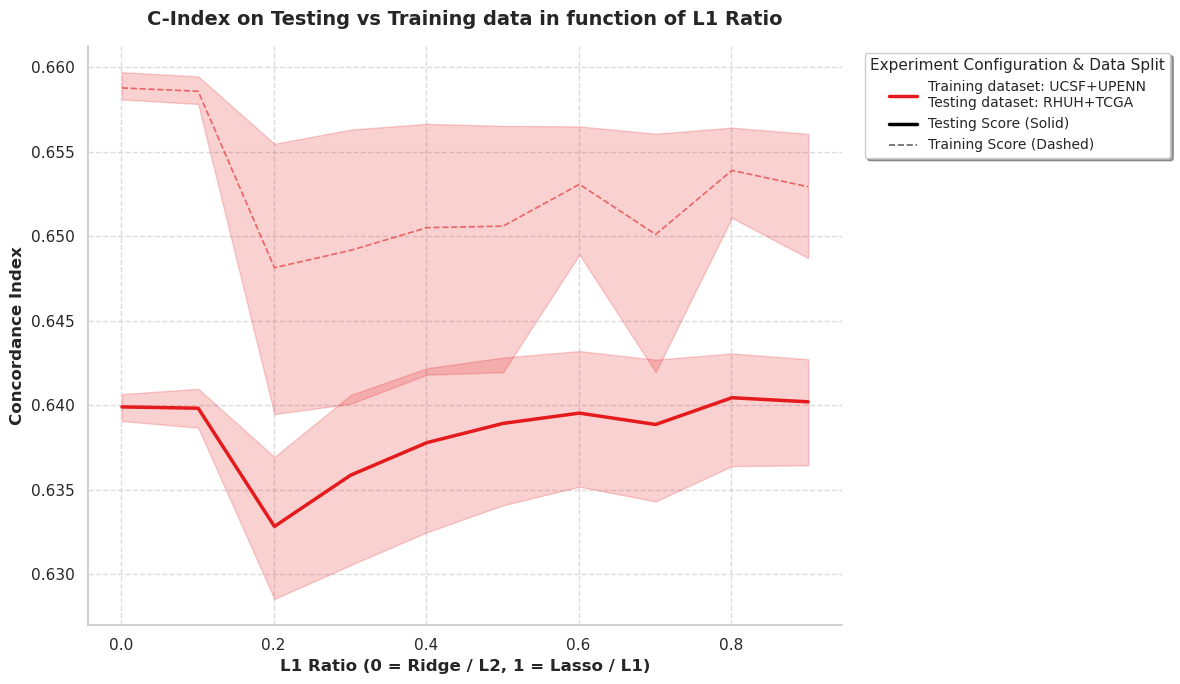

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# Zakładam, że kolumna 'training_testing_configuration' jest już w df, 
# ale dla bezpieczeństwa zostawiam tę linijkę
df['training_testing_configuration'] = "Training dataset: " + df['training_dataset'].str.upper() + "\nTesting dataset: " + df['testing_dataset'].str.upper()

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 7))

# ==========================================
# Linie dla zbioru TESTOWEGO (Zależność od l1_ratio)
# ==========================================
sns.lineplot(
    data=df, 
    x='l1_ratio', # ZMIANA: Zamiast 'penalizer', teraz patrzymy na 'l1_ratio'
    y='ci_testing', 
    hue='training_testing_configuration', 
    linewidth=2.5,
    palette='Set1',
    ax=ax
)

# ==========================================
# Linie dla zbioru TRENINGOWEGO (Zależność od l1_ratio)
# ==========================================
sns.lineplot(
    data=df, 
    x='l1_ratio', # ZMIANA: Zamiast 'penalizer', teraz patrzymy na 'l1_ratio'
    y='ci_training', 
    hue='training_testing_configuration', 
    linewidth=1.2,
    linestyle='--',
    alpha=0.6,
    palette='Set1',
    legend=False,
    ax=ax
)

# ZMIANA: Aktualizacja tytułów, żeby odzwierciedlały nową oś X
ax.set_title("C-Index on Testing vs Training data in function of L1 Ratio", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("L1 Ratio (0 = Ridge / L2, 1 = Lasso / L1)", fontsize=12, fontweight='bold')
ax.set_ylabel("Concordance Index", fontsize=12, fontweight='bold')

ax.grid(True, which='both', linestyle='--', alpha=0.7)

# Tworzenie sztucznej legendy (bez zmian)
handles, labels = ax.get_legend_handles_labels()

line_test = Line2D([0], [0], color='black', linewidth=2.5, label='Testing Score (Solid)')
line_train = Line2D([0], [0], color='black', linewidth=1.2, linestyle='--', alpha=0.6, label='Training Score (Dashed)')

handles.extend([line_test, line_train])
labels.extend(['Testing Score (Solid)', 'Training Score (Dashed)'])

ax.legend(
    handles=handles, 
    labels=labels, 
    title="Experiment Configuration & Data Split", 
    title_fontsize='11', 
    fontsize='10', 
    frameon=True, 
    shadow=True,
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

sns.despine(ax=ax)

plt.tight_layout()
plt.show()

ucsf+upenn training Concordance Index: 0.6136
ucsf+upenn testing Concordance Index: 0.6136


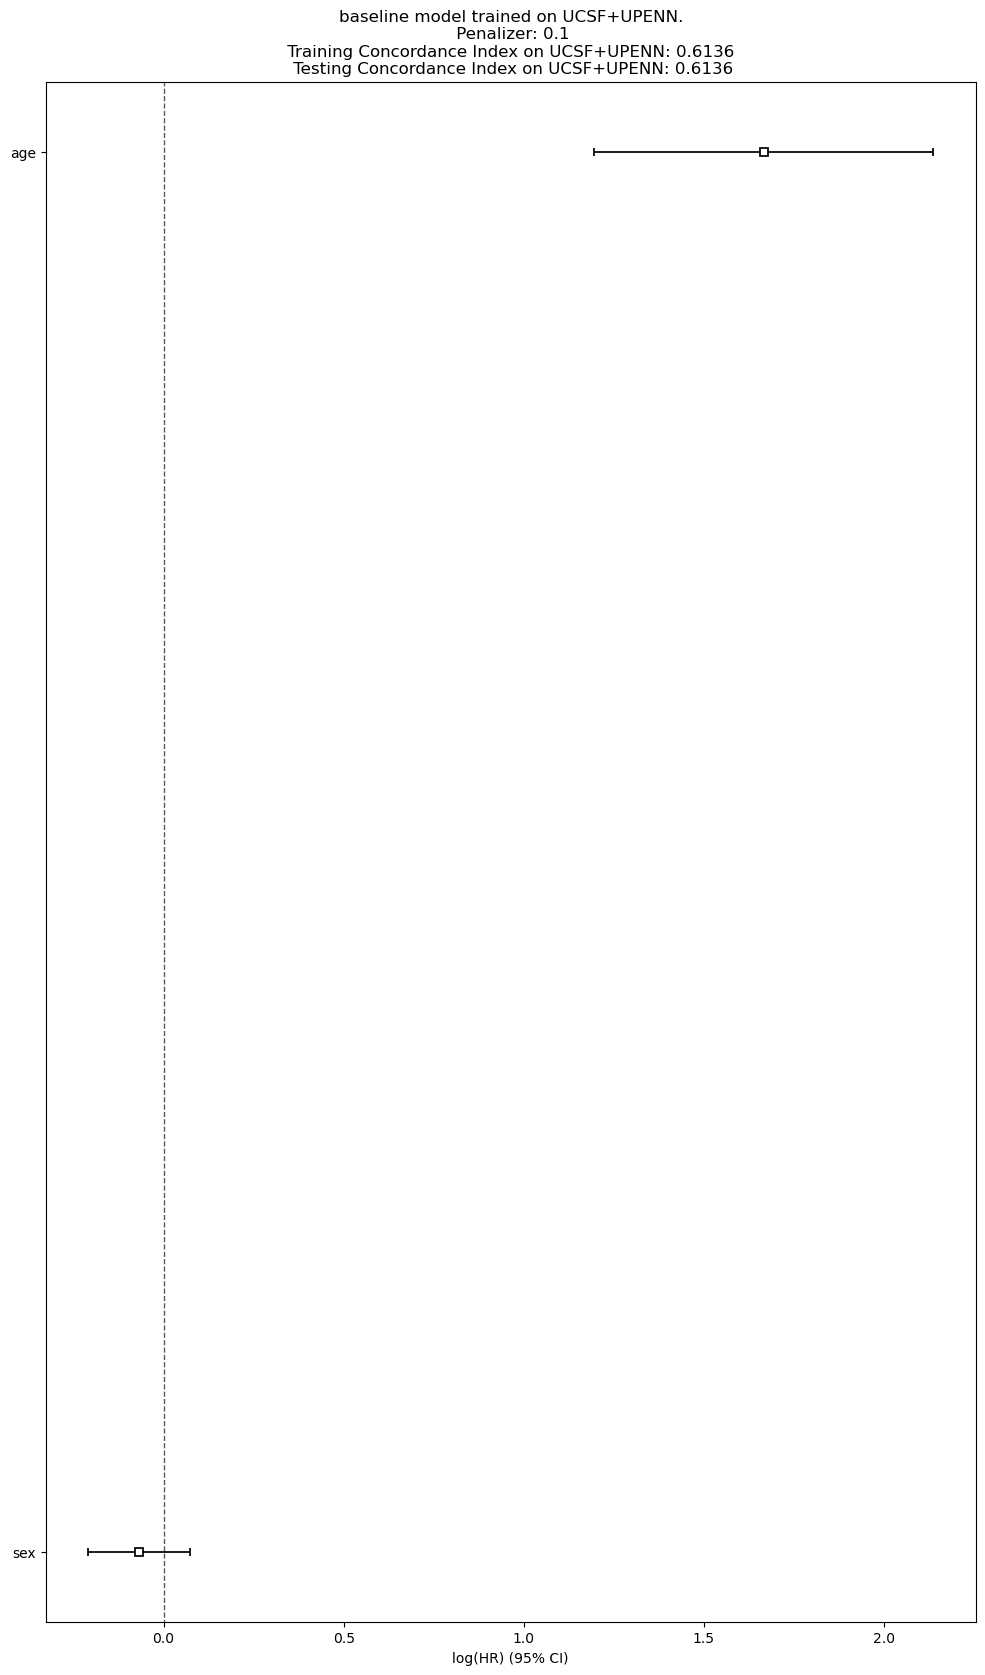

In [ ]:
from TractDensityComponents import TD_PCA
from components import Projections
from nmf import NMFProjections

import sklearn

normalization = None#'min_max'
# save_dir = "results/"
n_components = 100

sklearn.set_config(transform_output="default")

UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()

penalizer = 0.1
duration_col = 'OS (corrected)'
event_col = 'status'

# dataset_training = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_testing = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# dataset_testing = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_training = Dataset("upenn", "path/2", maps_upenn, data_upenn)
dataset_training = Dataset("ucsf+upenn", "path/3", maps_all, DATA)
dataset_testing = Dataset("ucsf+upenn", "path/3", maps_all, DATA)


df_training = dataset_training.df
df_testing = dataset_testing.df

training_maps = dataset_training.maps
testing_maps = dataset_testing.maps


df_base = df_training
df_base = df_base.drop(columns=["OS", "site", "EOR", "MGMT", "volume", "tdi", "ltdi"])


encoding_pipeline = EncodingPipeline(df_base)
X_train = DataTransformer.feature_fit_transform(encoding_pipeline)


td_cphfitter = TD_CoxPHFitter(penalizer)
td_cphfitter.fit(X_train, duration_col, event_col)

print(f"{dataset_training.name} training Concordance Index: {td_cphfitter.concordance_index:.4f}")

df_base = df_testing
df_base = df_base.drop(columns=["OS", "site", "EOR", "MGMT", "volume", "tdi", "ltdi"])
X_test = DataTransformer.feature_transform(df_base, encoding_pipeline)

c_index_test = td_cphfitter.score(X_test, "concordance_index")
print(f"{dataset_testing.name} testing Concordance Index: {c_index_test:.4f}")

fig, ax = plt.subplots(figsize=(12, 20))
ax.set_title(f"baseline model trained on {dataset_training.name.upper()}.\n Penalizer: {penalizer}\n Training Concordance Index on {dataset_training.name.upper()}: {td_cphfitter.concordance_index:.4f} \n Testing Concordance Index on {dataset_testing.name.upper()}: {c_index_test:.4f}")
td_cphfitter.plot(ax = ax)

INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
INFO:	TD maps were masked.
INFO:	Transforming maps without applying any normalization . . .
INFO:	Maps transformed sucessfully!
ucsf training Concordance Index: 0.7851
upenn testing Concordance Index: 0.5932


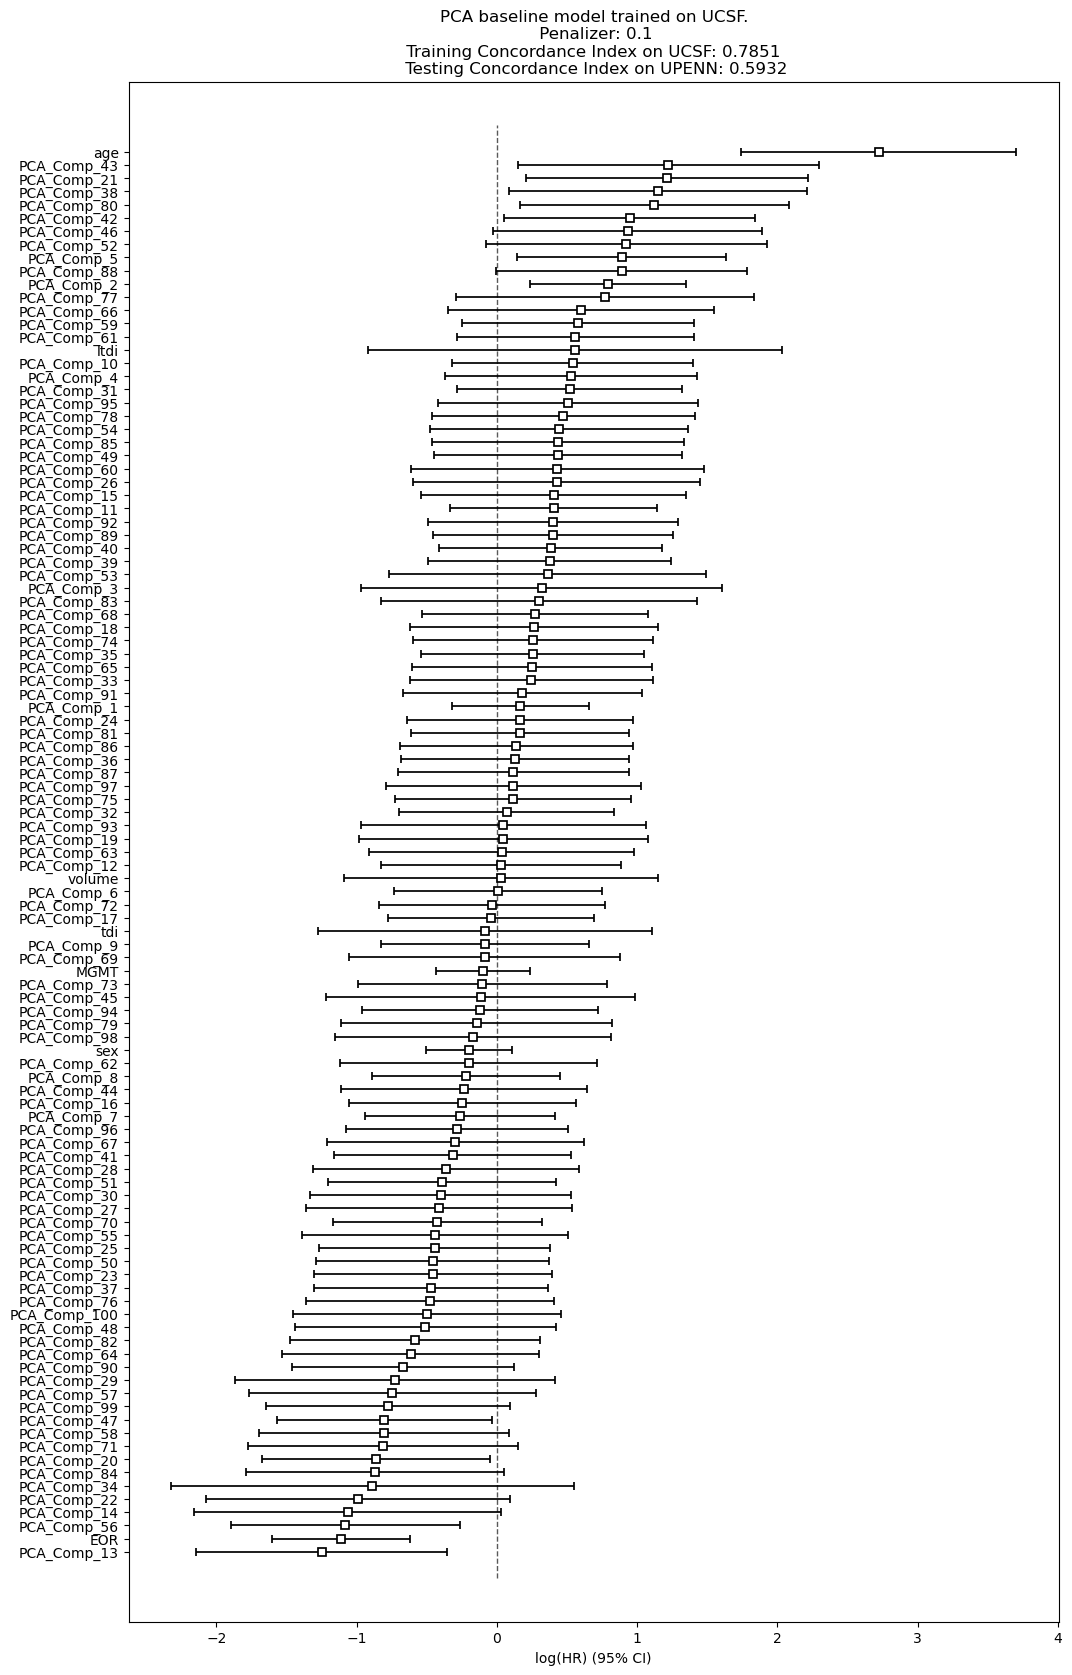

In [114]:
from TractDensityComponents import TD_PCA
from components import Projections
from nmf import NMFProjections

import sklearn

normalization = None#'min_max'
# save_dir = "results/"
n_components = 100

sklearn.set_config(transform_output="default")

UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()

penalizer = 0.1
duration_col = 'OS (corrected)'
event_col = 'status'

dataset_training = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
dataset_testing = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# dataset_testing = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_training = Dataset("upenn", "path/2", maps_upenn, data_upenn)

df_training = dataset_training.df
df_testing = dataset_testing.df

training_maps = dataset_training.maps
testing_maps = dataset_testing.maps

# method = TD_Kernel_PCA(training_maps, T1, binary_mask=T1_brain, n_components=n_components, kernel='cosine', gamma=0.1)
method = TD_PCA(training_maps, T1, binary_mask=T1_brain, n_components=n_components)
# method = NMFProjections(training_maps, template=T1, binary_mask=T1_brain, n_components=n_components, max_iter=10)
trainer = Transformer(method)

comps_training = trainer.fit_transform(norm=normalization)
comps_testing = trainer.transform(testing_maps)

df_base = df_training
df_base = df_base.drop(columns=["OS", "site"])


X_train_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_training, method, n_components=n_components)
# df_base = DataTransformer.drop_columns(X_train_with_features)
encoding_pipeline = EncodingPipeline(X_train_with_features)
X_train = DataTransformer.feature_fit_transform(encoding_pipeline)


td_cphfitter = TD_CoxPHFitter(penalizer)
td_cphfitter.fit(X_train, duration_col, event_col)

print(f"{dataset_training.name} training Concordance Index: {td_cphfitter.concordance_index:.4f}")

df_base = df_testing
df_base = df_base.drop(columns=["OS", "site"])
# X_test_with_features = DataHelper.add_extracted_mapsdata(df_base, comps_testing, method, n_components)
# X_test = DataHelper.feature_transform(X_test_with_features, )
X_test_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_testing, method, n_components=n_components)
X_test = DataTransformer.feature_transform(X_test_with_features, encoding_pipeline)

c_index_test = td_cphfitter.score(X_test, "concordance_index")
print(f"{dataset_testing.name} testing Concordance Index: {c_index_test:.4f}")

fig, ax = plt.subplots(figsize=(12, 20))
ax.set_title(f"{method} baseline model trained on {dataset_training.name.upper()}.\n Penalizer: {penalizer}\n Training Concordance Index on {dataset_training.name.upper()}: {td_cphfitter.concordance_index:.4f} \n Testing Concordance Index on {dataset_testing.name.upper()}: {c_index_test:.4f}")
td_cphfitter.plot(ax = ax)